# Лабораторная работа №1. Регрессия

## Предсказание качества вина (Wine Quality)

**Цель:** исследовать характеристики вина, обучить и сравнить модели регрессии для предсказания оценки `quality`.

**Данные:** Wine Quality (UCI), красное и белое вино.

**Метрики:** RMSE (основная) и MAE. Целевой порог: RMSE < 0.70.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем данные
red_df = pd.read_csv("winequality-red.csv", sep=";")
white_df = pd.read_csv("winequality-white.csv", sep=";")

# Добавляем бинарный признак типа вина
red_df["wine_type"] = 0
white_df["wine_type"] = 1

# Объединяем красное и белое вино
df = pd.concat(
    [red_df, white_df],
    ignore_index=True
)

print("Красное вино:", len(red_df))
print("Белое вино:", len(white_df))
print("Размер датасета:", df.shape)

display(df.head())


Красное вино: 1599
Белое вино: 4898
Размер датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [2]:

# Проверяем пропуски
print("Количество пропусков:")
print(df.isnull().sum())

# Проверяем дубликаты
print("\nПолных дубликатов:", df.duplicated().sum())

# Проверяем количество уникальных строк
print("Уникальных строк:", len(df.drop_duplicates()))

# Проверяем одинаковые признаки с разными оценками
feature_cols = df.drop(columns=["quality"]).columns.tolist()

quality_counts = df.groupby(feature_cols)["quality"].nunique()

print(
    "Наборов одинаковых признаков с разными оценками:",
    (quality_counts > 1).sum()
)


Количество пропусков:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Полных дубликатов: 1177
Уникальных строк: 5320
Наборов одинаковых признаков с разными оценками: 0


## 1. Загрузка и предварительная обработка данных

Исходный набор содержит 6497 образцов и 13 столбцов: 11 химических характеристик, `wine_type` (0 — красное, 1 — белое) и целевую переменную `quality`.

Пропусков нет. Найдено 1177 полных дубликатов, а одинаковых наборов признаков с разными оценками не обнаружено. Для исключения повторов между обучением и тестированием дубликаты удалены до разделения данных; осталось **5320 уникальных строк**.

In [3]:

# Удаляем полностью одинаковые строки
df = df.drop_duplicates().reset_index(drop=True)

# Проверяем результат
print("Размер очищенного датасета:", df.shape)
print("Осталось дубликатов:", df.duplicated().sum())

display(df.head())


Размер очищенного датасета: (5320, 13)
Осталось дубликатов: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


## 2. Подготовка выборок

### 2.1. Разделение на обучающую и тестовую выборки

Уникальные наблюдения разделены на **80% для обучения (4256)** и **20% для тестирования (1064)**. Бóльшая часть доступна для обучения, а отдельная тестовая часть — для финальной проверки. Стратификация по дискретной оценке `quality` сохраняет приблизительные пропорции оценок; `random_state=42` обеспечивает воспроизводимость.

Для сравнения алгоритмов используется кросс-валидация только на обучающих данных. Подбор по повторным тестовым оценкам приводит к подстройке под тест и может завышать ожидаемое качество на новых данных.

In [4]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (4256, 12)
X_test: (1064, 12)
y_train: (4256,)
y_test: (1064,)


In [5]:
# Создаём таблицу только из обучающих данных
train_df = X_train.copy()
train_df["quality"] = y_train

print("Размер обучающей выборки:", train_df.shape)


Размер обучающей выборки: (4256, 13)


## 3. Исследовательский анализ данных

### 3.1. Распределение качества

Рассмотрим частоты оценок `quality`, чтобы выявить преобладающие и редкие значения.

,count
quality,
3,24
4,165
5,1402
6,1858
7,685
8,118
9,4


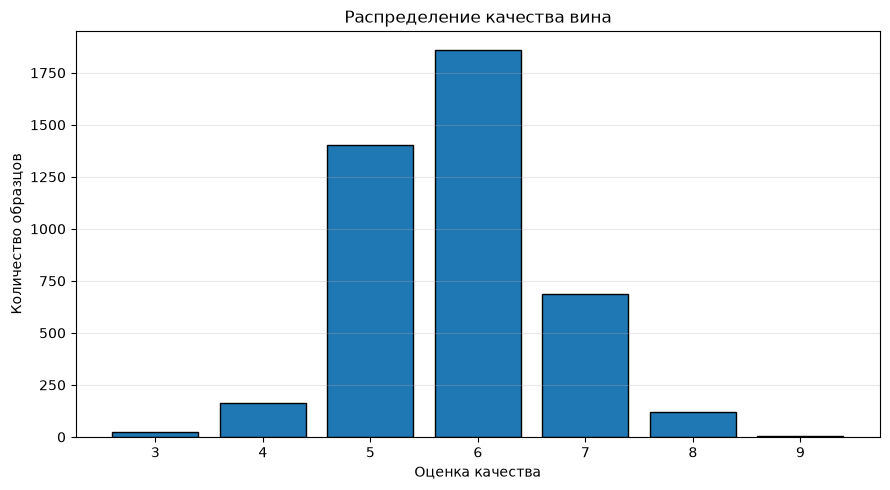

In [6]:

# Подсчитываем количество вин каждой оценки
quality_counts = train_df["quality"].value_counts().sort_index()

display(
    quality_counts.to_frame(name="count")
)

# Строим график
plt.figure(figsize=(9, 5))

plt.bar(
    quality_counts.index,
    quality_counts.values,
    edgecolor="black"
)

plt.title("Распределение качества вина")
plt.xlabel("Оценка качества")
plt.ylabel("Количество образцов")
plt.xticks(quality_counts.index)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


В обучающей выборке преобладают оценки качества 5 и 6 (около 76,6% наблюдений). Крайние оценки встречаются значительно реже: качество 3 имеют 24 образца, а качество 9 — всего 4.

Такое неравномерное распределение может затруднять предсказание редких оценок качества.

### 3.2. Описательная статистика

Рассчитаем средние значения, стандартные отклонения, квартили и диапазоны химических признаков.

In [7]:

# Описательная статистика химических характеристик
features = train_df.drop(columns=["quality", "wine_type"])

display(features.describe().round(3))


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,4256.000,4256.000,4256.000,4256.000,4256.000,4256.000,4256.000,4256.000,4256.000,4256.000,4256.000
mean,7.225,0.343,0.319,5.002,0.057,29.992,113.737,0.995,3.224,0.533,10.568
std,1.332,0.167,0.147,4.450,0.036,17.824,56.554,0.003,0.160,0.146,1.191
min,4.200,0.080,0.000,0.600,0.009,1.000,7.000,0.987,2.720,0.220,8.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,74.000,0.992,3.110,0.430,9.500
50%,7.000,0.300,0.310,2.700,0.047,28.000,115.750,0.995,3.210,0.510,10.400
75%,7.700,0.410,0.390,7.400,0.066,40.125,153.000,0.997,3.330,0.600,11.400
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,1.980,14.900


Признаки имеют разные масштабы значений. Например, `density` находится около 0.995, а `total sulfur dioxide` достигает 440.

Для `residual sugar` среднее значение составляет 5.002, а медиана — 2.7. Это указывает на правостороннюю асимметрию распределения.

Различия в масштабах признаков необходимо учитывать при интерпретации коэффициентов линейной регрессии.

### 3.3. Корреляции с качеством

Корреляции с целевой переменной рассчитываются только на обучающей выборке, чтобы не использовать тестовые ответы при анализе связей между признаками и качеством вина.

Коэффициент корреляции Пирсона показывает направление и силу линейной связи. При этом корреляция не доказывает причинно-следственную зависимость.

,correlation_with_quality
density,-0.328
volatile acidity,-0.256
chlorides,-0.201
fixed acidity,-0.080
residual sugar,-0.065
total sulfur dioxide,-0.061
sulphates,0.045
free sulfur dioxide,0.049
pH,0.051
citric acid,0.094


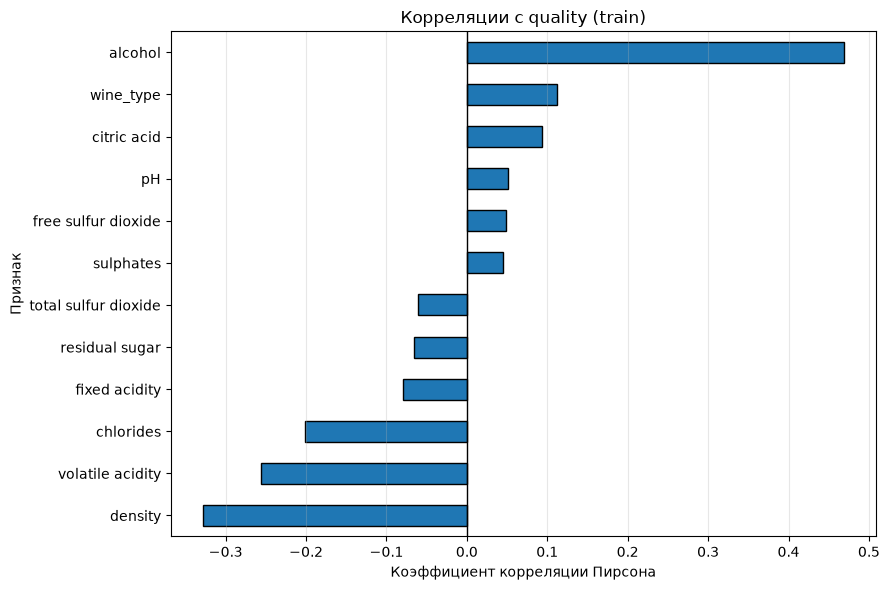

In [25]:

# Корреляции рассчитываем только на обучающей выборке

corr = train_df.corr(numeric_only=True)

quality_corr = (
    corr["quality"]
    .drop("quality")
    .sort_values()
)

display(
    quality_corr.to_frame(
        name="correlation_with_quality"
    ).round(3)
)

plt.figure(figsize=(9, 6))

quality_corr.plot(
    kind="barh",
    edgecolor="black"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Корреляции с quality (train)")
plt.xlabel("Коэффициент корреляции Пирсона")
plt.ylabel("Признак")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


Наиболее сильная положительная корреляция с `quality` наблюдается у `alcohol` (0.469). Отрицательные корреляции характерны для `density` (−0.328), `volatile acidity` (−0.256) и `chlorides` (−0.201).

Эти характеристики могут быть полезны для предсказания качества вина. При этом слабая линейная корреляция не исключает наличия нелинейных зависимостей.

## 4. Обучение и сравнение моделей

### 4.1. Метрики

Средняя абсолютная ошибка:

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|.
$$

Корень из средней квадратичной ошибки:

$$
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}.
$$

Здесь $y_i$ — истинное качество, $\hat y_i$ — прогноз. MAE показывает среднюю величину отклонения, а RMSE сильнее реагирует на крупные ошибки из-за возведения в квадрат. Поэтому для одной модели RMSE может заметно превышать MAE. **Чем меньше обе метрики, тем лучше.**

### 4.2. Baseline и кросс-валидация

Baseline (`DummyRegressor`) предсказывает среднее значение `quality` на текущей обучающей части:

$$
\hat y=\bar y_{train}.
$$

Среднее — оптимальная константа для RMSE; для MAE такой константой была бы медиана.

Для сравнения моделей используем **5-fold CV**: обучение на четырёх фолдах и оценку на пятом, с последующим усреднением пяти значений метрики. Разбиения одинаковы для всех алгоритмов; тестовые объекты в CV не участвуют.

In [10]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

# Одинаковые разбиения для всех моделей
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Метрики для сравнения моделей
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

# Baseline: прогнозирование среднего значения
baseline_model = DummyRegressor(strategy="mean")

# Кросс-валидация только на обучающих данных
baseline_cv = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Получаем средние значения ошибок
baseline_mae = -baseline_cv["test_MAE"].mean()
baseline_rmse = -baseline_cv["test_RMSE"].mean()

print("Baseline CV MAE:", round(baseline_mae, 4))
print("Baseline CV RMSE:", round(baseline_rmse, 4))


Baseline CV MAE: 0.6949
Baseline CV RMSE: 0.8796


Baseline получил **CV MAE = 0.6949**, **CV RMSE = 0.8796**. Это отправная точка для оценки улучшений; порог RMSE < 0.70 не достигнут.

### 4.3. Линейная регрессия

`LinearRegression` предсказывает качество как линейную комбинацию признаков:

$$
\hat y_i=b_0+\sum_{j=1}^{m}b_jx_{ij}.
$$

Коэффициенты подбираются минимизацией суммы квадратов ошибок. Для сравнения используется та же пятикратная кросс-валидация.

In [11]:

from sklearn.linear_model import LinearRegression

# Создаём модель линейной регрессии
linear_model = LinearRegression()

# Кросс-валидация на обучающей выборке
linear_cv = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Средние значения метрик
linear_mae = -linear_cv["test_MAE"].mean()
linear_rmse = -linear_cv["test_RMSE"].mean()

print("Linear Regression CV MAE:", round(linear_mae, 4))
print("Linear Regression CV RMSE:", round(linear_rmse, 4))


Linear Regression CV MAE: 0.5645
Linear Regression CV RMSE: 0.7327


Линейная регрессия получила **CV MAE = 0.5645**, **CV RMSE = 0.7327**. Она лучше Baseline, но пока не достигла RMSE < 0.70; возможны нелинейные связи, не описываемые линейной моделью.

#### Коэффициенты линейной регрессии

Знак коэффициента показывает направление изменения прогноза при фиксированных остальных признаках. Коэффициенты разных по масштабу признаков нельзя напрямую сравнивать.

Для сопоставления рассчитываем изменение прогноза при увеличении признака на одно стандартное отклонение:

$$
b_j^{*}=b_j\sigma_j,
$$

где $\sigma_j$ вычислено на `X_train`. Для обычной линейной регрессии масштабирование не обязательно, но полезно для интерпретации коэффициентов; оно также может улучшать численную устойчивость.

In [12]:

# Обучаем линейную регрессию на всей обучающей выборке
linear_model.fit(X_train, y_train)

# Получаем коэффициенты
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": linear_model.coef_,
    "standardized_coefficient": (
        linear_model.coef_ * X_train.std(ddof=0).to_numpy()
    )
})

# Сортируем по модулю стандартизированного коэффициента
coef_df["abs_coef"] = coef_df["standardized_coefficient"].abs()

coef_df = coef_df.sort_values(
    "abs_coef",
    ascending=False
)

display(coef_df.round(4))


,feature,coefficient,standardized_coefficient,abs_coef
7,density,-94.7183,-0.2810,0.2810
10,alcohol,0.2314,0.2755,0.2755
3,residual sugar,0.0510,0.2268,0.2268
1,volatile acidity,-1.3258,-0.2209,0.2209
9,sulphates,0.8040,0.1174,0.1174
11,wine_type,-0.2604,-0.1137,0.1137
5,free sulfur dioxide,0.0063,0.1118,0.1118
8,pH,0.6656,0.1067,0.1067
6,total sulfur dioxide,-0.0019,-0.1054,0.1054
0,fixed acidity,0.0731,0.0973,0.0973


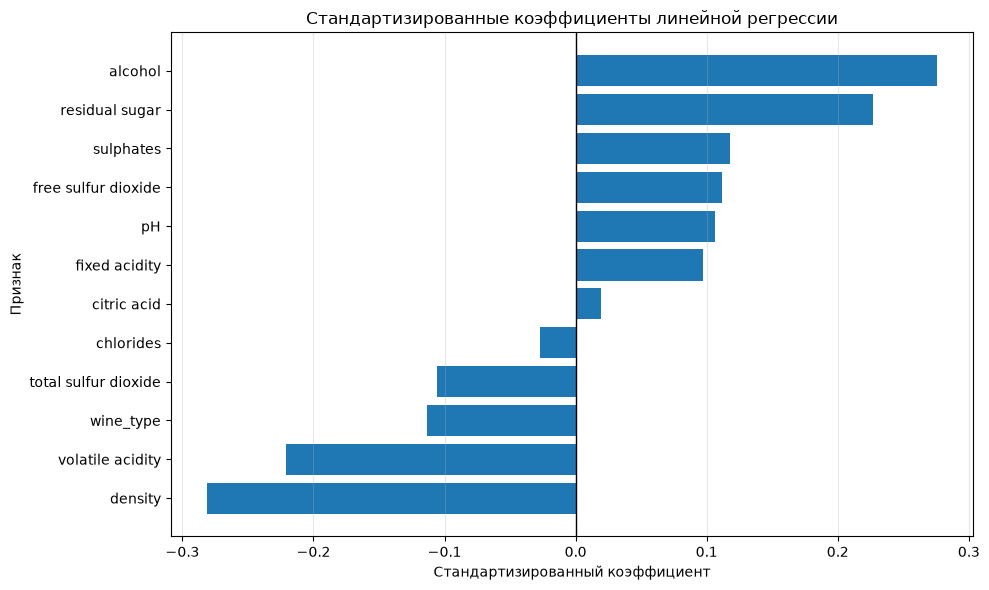

In [13]:

# Сортируем коэффициенты для графика
coef_plot = coef_df.sort_values(
    "standardized_coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    coef_plot["feature"],
    coef_plot["standardized_coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Стандартизированные коэффициенты линейной регрессии")
plt.xlabel("Стандартизированный коэффициент")
plt.ylabel("Признак")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


Наибольшие по модулю коэффициенты в сопоставимом масштабе: `density` (−0.2810), `alcohol` (+0.2755), `residual sugar` (+0.2268), `volatile acidity` (−0.2209). Взаимосвязи признаков могут влиять на коэффициенты; они не описывают причинное влияние.

### 4.4. Random Forest

Random Forest (случайный лес) — ансамблевый алгоритм, который объединяет предсказания нескольких деревьев решений. Деревья позволяют учитывать нелинейные зависимости между признаками, а усреднение их предсказаний уменьшает разброс и повышает устойчивость модели.

In [14]:

from sklearn.ensemble import RandomForestRegressor

# Создаём случайный лес
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Проводим кросс-валидацию
rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Рассчитываем средние значения метрик
rf_mae = -rf_cv["test_MAE"].mean()
rf_rmse = -rf_cv["test_RMSE"].mean()

print("Random Forest CV MAE:", round(rf_mae, 4))
print("Random Forest CV RMSE:", round(rf_rmse, 4))


Random Forest CV MAE: 0.5343
Random Forest CV RMSE: 0.6964


Random Forest получил **CV MAE = 0.5343**, **CV RMSE = 0.6964**, улучшив результаты Baseline и линейной регрессии. Средний CV RMSE ниже 0.70, но итоговое качество оценивается отдельно на тесте.

#### Важность признаков Random Forest

`feature_importances_` отражает относительный вклад признаков в уменьшение критерия разбиения деревьев. Значения суммируются в 1, но **не являются оценкой причинного воздействия**.

,feature,importance
10,alcohol,0.2597
1,volatile acidity,0.1173
5,free sulfur dioxide,0.0918
9,sulphates,0.0786
6,total sulfur dioxide,0.0769
8,pH,0.0714
3,residual sugar,0.0667
4,chlorides,0.0647
2,citric acid,0.0585
0,fixed acidity,0.0585


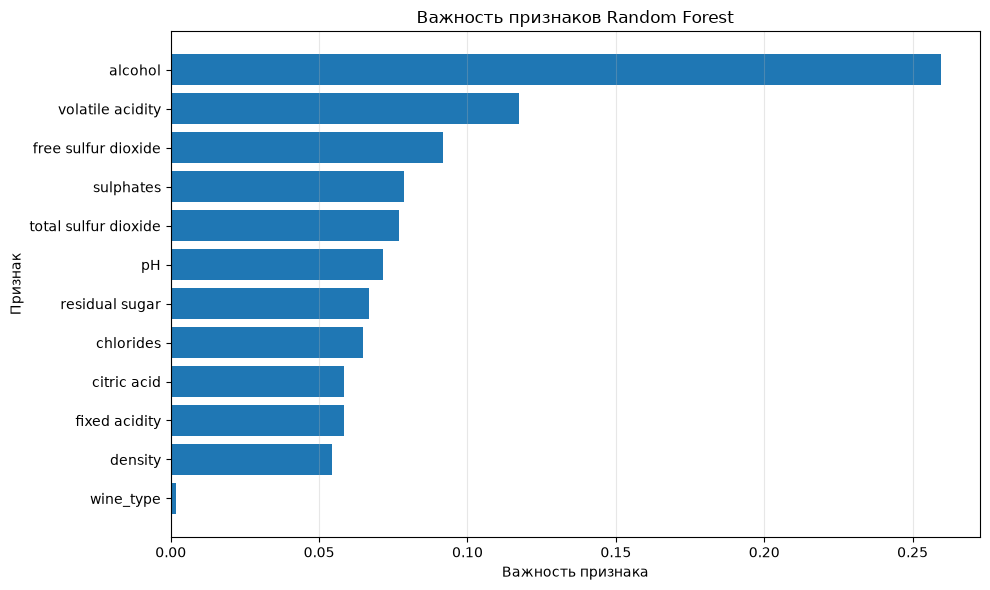

In [15]:

# Обучаем модель на всей обучающей выборке
rf_model.fit(X_train, y_train)

# Получаем важность признаков
rf_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

# Сортируем по убыванию
rf_importance = rf_importance.sort_values(
    "importance",
    ascending=False
)

display(rf_importance.round(4))

# Строим график
plt.figure(figsize=(10, 6))

plt.barh(
    rf_importance["feature"],
    rf_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Важность признаков Random Forest")
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


Наиболее важны `alcohol` (0.2597), `volatile acidity` (0.1173) и `free sulfur dioxide` (0.0918). Это частично согласуется с EDA и линейной регрессией, где выделялись `alcohol` и `volatile acidity`. При этом `density` имела заметную корреляцию и крупный коэффициент линейной регрессии, но небольшую важность в лесу (0.0543): методы оценивают разные виды вклада признаков.

### 4.5. Gradient Boosting

`GradientBoostingRegressor` строит деревья последовательно: каждое новое дерево корректирует ошибки текущего ансамбля. Используются 100 деревьев глубиной 3, `learning_rate=0.1` и та же схема CV.

In [16]:

from sklearn.ensemble import GradientBoostingRegressor

# Создаём модель градиентного бустинга
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Кросс-валидация на обучающих данных
gb_cv = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Средние значения метрик
gb_mae = -gb_cv["test_MAE"].mean()
gb_rmse = -gb_cv["test_RMSE"].mean()

print("Gradient Boosting CV MAE:", round(gb_mae, 4))
print("Gradient Boosting CV RMSE:", round(gb_rmse, 4))


Gradient Boosting CV MAE: 0.5469
Gradient Boosting CV RMSE: 0.7067


Gradient Boosting получил **CV MAE = 0.5469**, **CV RMSE = 0.7067**. Он лучше Baseline и линейной регрессии, но немного уступает Random Forest по RMSE.

#### Важность признаков Gradient Boosting

Исследуем `feature_importances_` бустинга и сравним их с Random Forest и корреляциями.

,feature,importance
10,alcohol,0.4679
1,volatile acidity,0.1403
5,free sulfur dioxide,0.1133
9,sulphates,0.0619
6,total sulfur dioxide,0.0436
4,chlorides,0.0351
8,pH,0.0323
0,fixed acidity,0.0283
2,citric acid,0.0279
3,residual sugar,0.0266


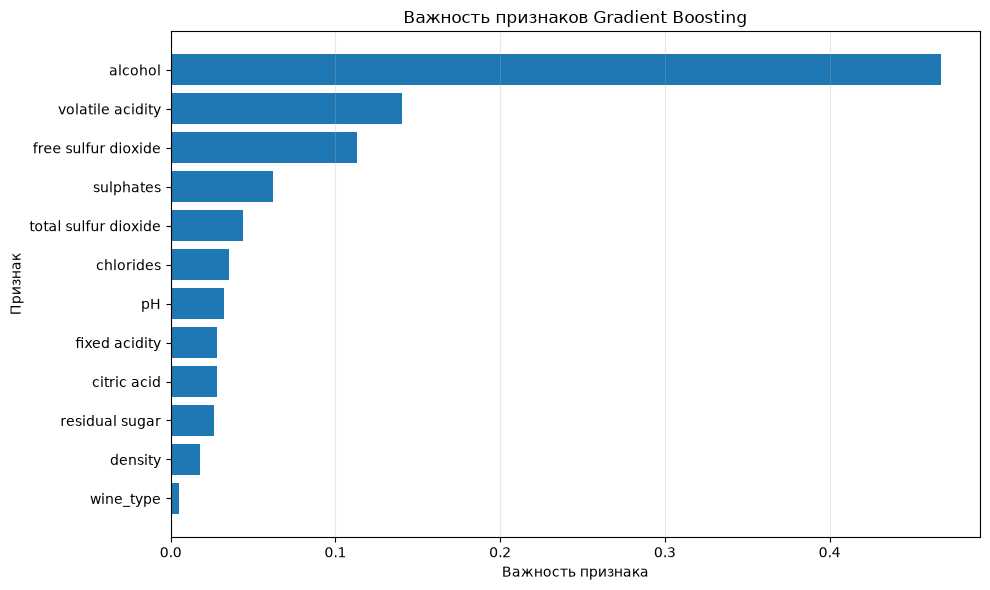

In [17]:

# Обучаем Gradient Boosting на всей обучающей выборке
gb_model.fit(X_train, y_train)

# Получаем важность признаков
gb_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": gb_model.feature_importances_
})

# Сортируем признаки по убыванию важности
gb_importance = gb_importance.sort_values(
    "importance",
    ascending=False
)

display(gb_importance.round(4))

# Строим график
plt.figure(figsize=(10, 6))

plt.barh(
    gb_importance["feature"],
    gb_importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("Важность признаков Gradient Boosting")
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


Обе ансамблевые модели выделяют одинаковую тройку: `alcohol`, `volatile acidity`, `free sulfur dioxide`. В бустинге относительная важность `alcohol` выше (0.4679 против 0.2597 у леса).

Важность признаков не доказывает их причинного влияния на качество вина. Признаки взаимосвязаны, а данные получены наблюдением, без контролируемого изменения состава вина. Поэтому высокая важность признака означает его полезность для предсказания, но не доказывает, что изменение этого признака само по себе изменит качество вина.

## 5. Сравнение и выбор алгоритма

Сравним средние MAE и RMSE по пяти фолдам. **Основной критерий выбора — минимальный CV RMSE**; тестовые ответы при выборе не используются.

In [18]:

# Сравниваем результаты кросс-валидации
cv_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "CV MAE": [
        baseline_mae,
        linear_mae,
        rf_mae,
        gb_mae
    ],
    "CV RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        gb_rmse
    ]
})

cv_results = cv_results.sort_values(
    "CV RMSE"
).reset_index(drop=True)

display(cv_results.round(4))

# Выбираем лучший алгоритм по RMSE
best_model_name = cv_results.loc[0, "Model"]

print("Лучшая модель по CV:", best_model_name)


,Model,CV MAE,CV RMSE
0,Random Forest,0.5343,0.6964
1,Gradient Boosting,0.5469,0.7067
2,Linear Regression,0.5645,0.7327
3,Baseline,0.6949,0.8796


Лучшая модель по CV: Random Forest


По кросс-валидации все три регрессионные модели лучше Baseline. Наименьший RMSE получил **Random Forest (0.6964)**; у Gradient Boosting — 0.7067, у Linear Regression — 0.7327.

Ансамбли могут лучше учитывать нелинейные связи и взаимодействия характеристик вина. Для финального анализа ошибок **заранее выбран Random Forest**.

## 6. Финальная оценка

После выбора алгоритма все модели с зафиксированными параметрами обучаются на `X_train` и один раз оцениваются на общем отложенном `X_test` (1064 объекта). По тестовым результатам модели и параметры больше не выбираются.

In [19]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Объединяем модели с уже выбранными параметрами
models = {
    "Baseline": baseline_model,
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

test_results = []
predictions = {}

# Финальная оценка на тестовой выборке
for name, model in models.items():
    # Обучаем на всей обучающей выборке
    model.fit(X_train, y_train)

    # Предсказываем качество тестовых вин
    y_pred = model.predict(X_test)

    # Сохраняем предсказания
    predictions[name] = y_pred

    # Рассчитываем метрики
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    test_results.append({
        "Model": name,
        "Test MAE": mae,
        "Test RMSE": rmse
    })

# Итоговая таблица
test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))


,Model,Test MAE,Test RMSE
0,Baseline,0.6948,0.8801
1,Linear Regression,0.5660,0.7292
2,Random Forest,0.5347,0.6914
3,Gradient Boosting,0.5391,0.6943


На тесте все три обучаемые регрессионные модели лучше Baseline. **Random Forest показал лучший результат:** MAE = 0.5347, RMSE = 0.6914; у Gradient Boosting RMSE = 0.6943, у Linear Regression — 0.7292. Лес и бустинг достигли порога RMSE < 0.70 на локальном тесте. Это не гарантирует такой же результат на скрытой выборке преподавателя.

## 7. Анализ ошибок Random Forest

### 7.1. Распределение ошибок

Остаток определяется как

$$
e_i=y_i-\hat y_i.
$$

Положительное значение означает недооценку качества, отрицательное — переоценку. Рассмотрим распределение остатков и максимальную абсолютную ошибку.

In [20]:

# Получаем предсказания Random Forest,
# сохранённые при финальном тестировании
rf_pred = predictions["Random Forest"]

# Создаём таблицу ошибок
error_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": rf_pred
})

# Вычисляем ошибки
error_df["error"] = (
    error_df["actual"] - error_df["predicted"]
)

error_df["absolute_error"] = error_df["error"].abs()

display(error_df.head())

print("Средняя ошибка:", round(error_df["error"].mean(), 4))
print("MAE:", round(error_df["absolute_error"].mean(), 4))
print("Максимальная абсолютная ошибка:",
      round(error_df["absolute_error"].max(), 4))


,actual,predicted,error,absolute_error
0,5,5.52,-0.52,0.52
1,6,6.51,-0.51,0.51
2,6,6.36,-0.36,0.36
3,7,6.39,0.61,0.61
4,5,5.59,-0.59,0.59


Средняя ошибка: 0.0221
MAE: 0.5347
Максимальная абсолютная ошибка: 3.38


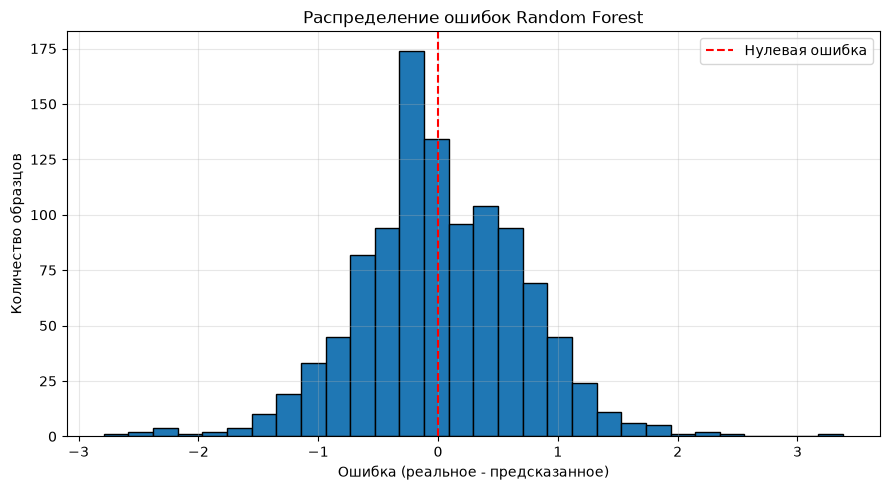

In [21]:

plt.figure(figsize=(9, 5))

plt.hist(
    error_df["error"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Нулевая ошибка"
)

plt.title("Распределение ошибок Random Forest")
plt.xlabel("Ошибка (реальное - предсказанное)")
plt.ylabel("Количество образцов")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Большинство ошибок близки к нулю. **Средняя ошибка = 0.0221**, **MAE = 0.5347**, а максимальная абсолютная ошибка достигает **3.38**. Небольшое среднее смещение не исключает крупных ошибок для отдельных вин.

### 7.2. Наибольшие ошибки

Рассмотрим десять объектов с наибольшими абсолютными ошибками вместе с их химическими характеристиками.

In [22]:

# Создаём копию тестовых данных
error_details = X_test.copy()

# Добавляем реальные и предсказанные оценки
error_details["actual"] = y_test
error_details["predicted"] = rf_pred

# Рассчитываем ошибки
error_details["error"] = (
    error_details["actual"] - error_details["predicted"]
)

error_details["absolute_error"] = (
    error_details["error"].abs()
)

# Выбираем десять самых больших ошибок
largest_errors = error_details.sort_values(
    "absolute_error",
    ascending=False
).head(10)

display(largest_errors.round(3))


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type,actual,predicted,error,absolute_error
2012,9.1,0.27,0.45,10.60,0.035,28.0,124.0,0.997,3.20,0.46,10.4,1,9,5.62,3.38,3.38
1982,6.9,0.39,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,1,3,5.79,-2.79,2.79
4984,5.8,0.26,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,1,4,6.55,-2.55,2.55
2549,8.2,0.22,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,1,8,5.46,2.54,2.54
2783,6.7,0.25,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,1,3,5.41,-2.41,2.41
4158,6.7,0.64,0.30,1.20,0.030,18.0,76.0,0.989,3.16,0.60,12.9,1,4,6.37,-2.37,2.37
3881,7.0,0.53,0.43,6.10,0.029,6.0,76.0,0.991,3.08,0.50,12.5,1,8,5.67,2.33,2.33
3337,6.9,0.15,0.28,4.40,0.029,14.0,107.0,0.993,3.24,0.46,10.4,1,8,5.71,2.29,2.29
1571,8.5,0.26,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,1,3,5.29,-2.29,2.29
1245,7.3,0.98,0.05,2.10,0.061,20.0,49.0,0.997,3.31,0.55,9.7,0,3,5.24,-2.24,2.24


Наибольшие ошибки наблюдаются преимущественно для редких оценок качества:

- Вино №2012: реальное качество 9, прогноз 5.62. Ошибка 3.38 может быть связана с тем, что оценка 9 крайне редко встречается в обучающих данных.
- Вино №1982: реальное качество 3, прогноз 5.79. Модель переоценила качество. Возможно, высокое содержание алкоголя (12.6%) повлияло на прогноз.
- Вино №2549: реальное качество 8, прогноз 5.46. Модель недооценила качество, предположительно из-за малого количества вин с оценкой 8 в обучающей выборке.

Таким образом, Random Forest склонен приближать редкие крайние оценки к наиболее распространённым значениям 5–6. Указанные причины являются предположениями, а не доказанными закономерностями.

### 7.3. Реальные и предсказанные оценки

Сравним значения `quality` с прогнозами. Пунктирная прямая $\hat y=y$ означает идеальное предсказание.

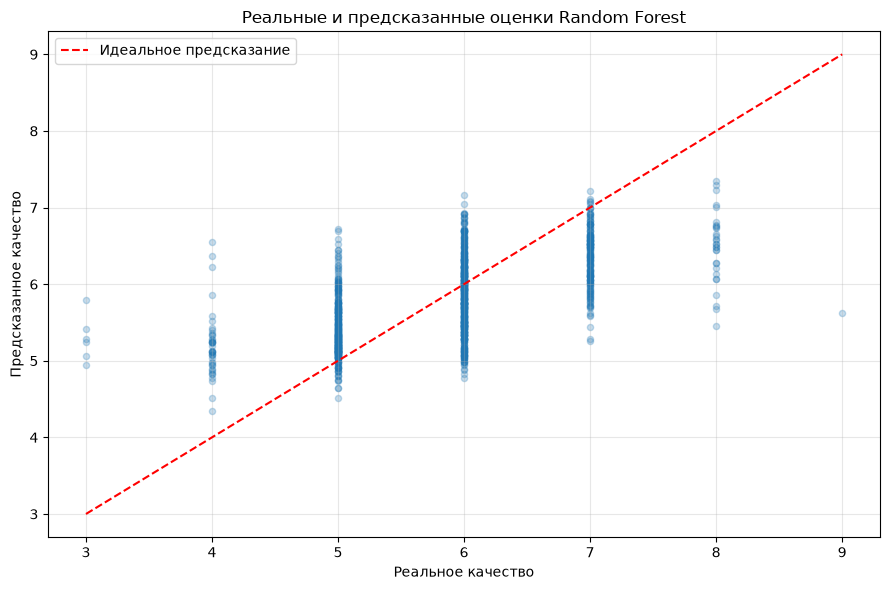

In [23]:

plt.figure(figsize=(9, 6))

# Реальные и предсказанные оценки
plt.scatter(
    y_test,
    rf_pred,
    alpha=0.25,
    s=20
)

# Линия идеальных предсказаний
plt.plot(
    [3, 9],
    [3, 9],
    color="red",
    linestyle="--",
    label="Идеальное предсказание"
)

plt.title("Реальные и предсказанные оценки Random Forest")
plt.xlabel("Реальное качество")
plt.ylabel("Предсказанное качество")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


На диаграмме видно смещение прогнозов к средним оценкам: качество 3–4 обычно переоценивается, а 8–9 — недооценивается. Одна из возможных причин — редкость крайних оценок в обучающих данных.

### 7.4. Ошибки по оценкам качества

Рассчитаем для каждой оценки число объектов, средний прогноз и MAE.

,count,mean_prediction,MAE
actual,,,
3,6,5.288,2.288
4,41,5.203,1.203
5,350,5.412,0.434
6,465,5.849,0.413
7,171,6.345,0.662
8,30,6.494,1.506
9,1,5.620,3.380


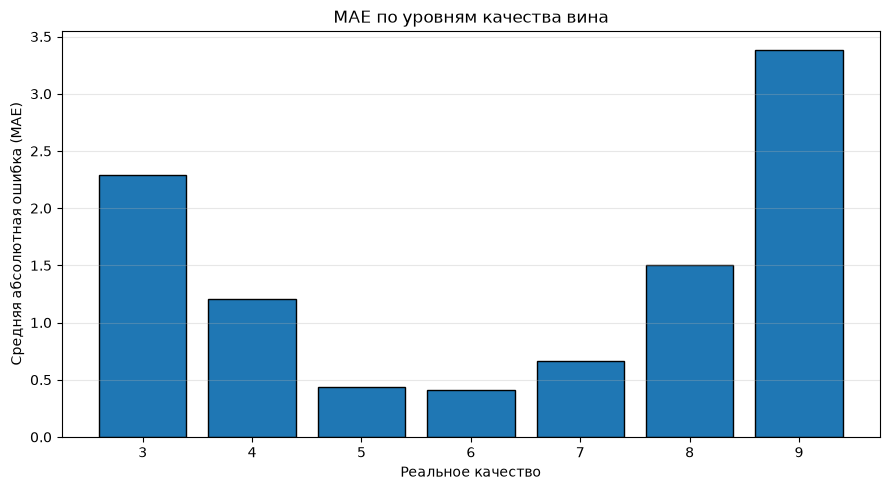

In [24]:

# Группируем ошибки по реальному качеству
errors_by_quality = error_df.groupby("actual").agg(
    count=("actual", "size"),
    mean_prediction=("predicted", "mean"),
    MAE=("absolute_error", "mean")
)

# Выводим таблицу
display(errors_by_quality.round(3))

# Строим график ошибок
plt.figure(figsize=(9, 5))

plt.bar(
    errors_by_quality.index,
    errors_by_quality["MAE"],
    edgecolor="black"
)

plt.title("MAE по уровням качества вина")
plt.xlabel("Реальное качество")
plt.ylabel("Средняя абсолютная ошибка (MAE)")
plt.xticks(errors_by_quality.index)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Наиболее низкая MAE для распространённых оценок 5 и 6 — **0.434 и 0.413**. Для редких оценок ошибки выше: при качестве 3 — **2.288**, при 8 — **1.506**, при 9 — **3.380**. В тесте лишь одно вино с оценкой 9, поэтому результат этой группы нельзя обобщать. Модель хуже предсказывает крайние оценки, смещая их к середине шкалы.

## 8. Заключение

После удаления 1177 дубликатов исследовано 5320 уникальных образцов Wine Quality. По пятикратной кросс-валидации из четырёх моделей выбран **Random Forest (CV RMSE = 0.6964)**. На отложенном тесте он получил **MAE = 0.5347 и RMSE = 0.6914**, выполнив локальный порог RMSE < 0.70.

Наиболее важны `alcohol`, `volatile acidity` и `free sulfur dioxide`. Основная слабость модели — большие ошибки для редких крайних оценок качества. Итог на скрытом тесте преподавателя может отличаться.